# ERC circularité · 02 · Flux d'entrée

**Question** : que contient le flux de déchets des ateliers, combien de FRU sont rebutées chaque semaine, et la masse estimée à partir des consommations est-elle confirmée par les pesées ?

**Décision éclairée** : à quelle granularité (quelle benne, quel type de déchet) le modèle de ligne peut être utilisé. Un flux dont l'estimation n'est pas confirmée par les pesées n'alimente pas le modèle.

Ce notebook présente, dans l'ordre, les deux tableaux demandés par le responsable du projet, puis le flux des FRU rebutées.

In [1]:
import sys
from pathlib import Path

# Le dossier est celui qui contient le code (erc/) : le parent de notebooks/.
dossier = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "erc" / "__init__.py").is_file()), Path.cwd().parent)
sys.path.insert(0, str(dossier))
import erc
from erc import affichage as aff

ctx = erc.executer(jusqua="flux")

ERC circularité — DÉMONSTRATION (données fictives)


  étape sources       3 artefacts → artefacts/00_sources/


  étape classement   13 artefacts → artefacts/01_classement/


  étape flux         14 artefacts → artefacts/02_flux/


In [2]:
aff.etat(ctx)

DÉMONSTRATION : toutes les données affichées sont fictives. Période : du 01/06/2026 au 01/11/2026, 154 jours extraits. Aucune anomalie de calcul.

## Tableau 1 · Composant, FRU, type de déchet

Une ligne par couple (FRU, composant) observé dans les consommations : type de déchet, benne, quantité et poids.

**Lecture** : pour un FRU donné, la table dit dans quelle benne part chaque pièce changée et quelle masse cela représente. **Limites** : le type de déchet et la benne viennent du classement matière, dont le niveau de preuve est indiqué ; une pièce sans poids unitaire a une masse vide, elle n'est pas comptée à zéro.

In [3]:
aff.table(ctx, "flux", "Composant FRU type de déchet", colonnes=["FRU", "Description FRU", "Atelier du FRU", "Référence", "Description", "Type de déchet", "Benne",
          "Pièces sur ce FRU", "Poids unitaire (kg)", "Source poids", "Niveau de preuve", "Kg sur ce FRU (poids connus)"])

FRU,Description FRU,Atelier du FRU,Référence,Description,Type de déchet,Benne,Pièces sur ce FRU,Poids unitaire (kg),Source poids,Niveau de preuve,Kg sur ce FRU (poids connus)
FRU-A100-R,Amplificateur de gradient (démo),MR,P-1003,AL Electrolytic Capacitor 450V 4700uF 105degC,Condensateur,DEEE,277,,,démo,
FRU-A100-R,Amplificateur de gradient (démo),MR,P-1001,IGBT 400A 1200V,Composant de puissance,DEEE,200,"0,350",pesée (démo),démo,"70,00"
FRU-A100-R,Amplificateur de gradient (démo),MR,P-1002,IGBT 400A 600V,Composant de puissance,DEEE,170,"0,350",pesée (démo),démo,"59,50"
FRU-A100-R,Amplificateur de gradient (démo),MR,P-1006,Bus resistance 33k ohm 10W,Composant standard,DEEE,119,"0,050",pesée (démo),démo,"5,95"
FRU-A100-R,Amplificateur de gradient (démo),MR,P-1004,Gate Driver Board,Carte B,DEEE,86,"0,400",pesée (démo),démo,"34,40"
FRU-A100-R,Amplificateur de gradient (démo),MR,P-1007,Protection fuse 100A high speed,Composant standard,DEEE,55,"0,080",pesée (démo),démo,"4,40"
FRU-A100-R,Amplificateur de gradient (démo),MR,P-1005,Control board assembly,Carte B,DEEE,31,"0,450",pesée (démo),démo,"13,95"
FRU-A200-R,Alimentation de puissance (démo),MR,P-2002,Cooling fan 120mm,Composant standard,DEEE,76,"0,250",pesée (démo),démo,"19,00"
FRU-A200-R,Alimentation de puissance (démo),MR,P-1002,IGBT 400A 600V,Composant de puissance,DEEE,74,"0,350",pesée (démo),démo,"25,90"
FRU-A200-R,Alimentation de puissance (démo),MR,P-2001,Power supply board,Carte B,DEEE,52,"0,600",pesée (démo),démo,"31,20"


La même information, résumée par benne et type de déchet. Un type dont aucune référence n'a de poids connu est écrit « poids inconnu » sur la figure ; dans la table, sa masse reste vide.

**Pièces et masse par type de déchet.** Ce que les ateliers consomment, rangé par benne puis par type de déchet : nombre de pièces et masse correspondante. Lecture : la masse n'est fiable que pour les types dont les poids unitaires sont connus.

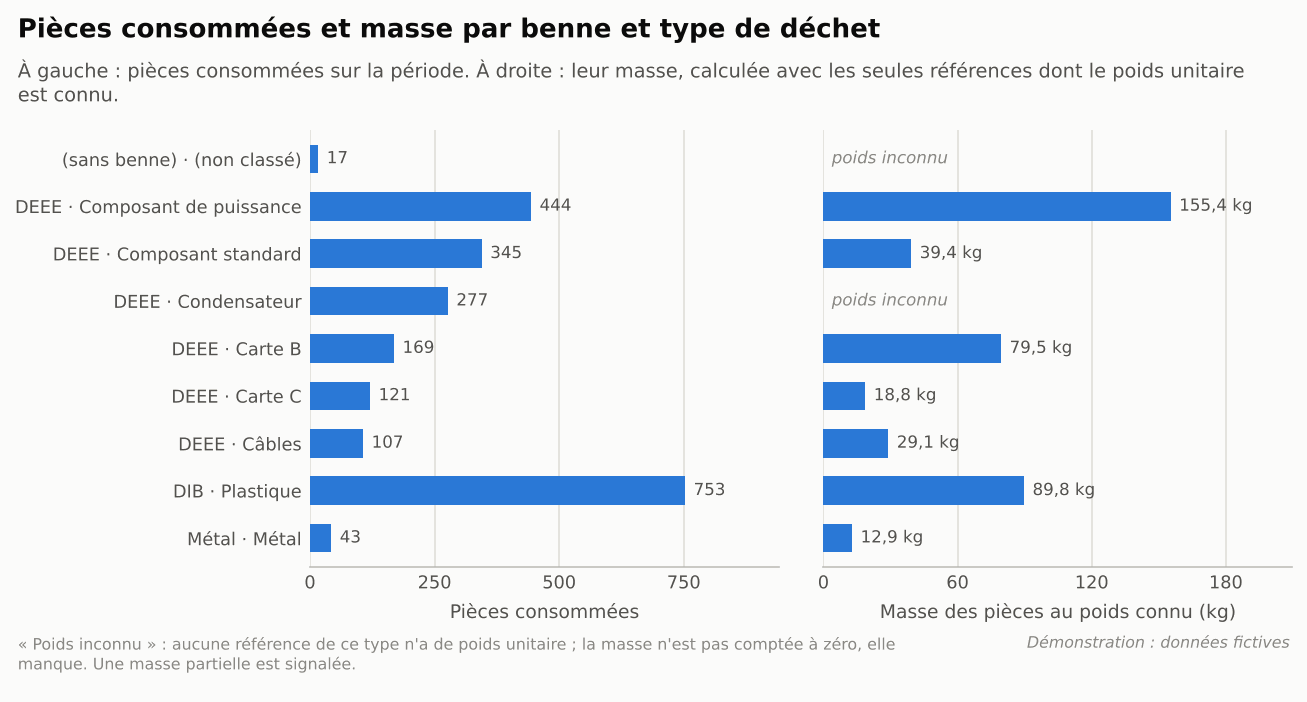

In [4]:
aff.figures(ctx, "flux", "Pièces et masse par type de déchet")

In [5]:
aff.table(ctx, "flux", "Synthèse par benne")

Benne,Type de déchet,Références,Pièces,Références au poids connu,Kg (poids connus)
DEEE,Carte B,3,169,3,"79,5"
DEEE,Carte C,2,121,2,"18,8"
DEEE,Composant de puissance,2,444,2,"155,4"
DEEE,Composant standard,4,345,4,"39,4"
DEEE,Condensateur,1,277,0,
DEEE,Câbles,2,107,2,"29,1"
DIB,Plastique,3,753,3,"89,8"
Métal,Métal,1,43,1,"12,9"
,,1,17,0,


## Tableau 2 · Estimé contre pesé

Pour chaque semaine et chaque flux : la valeur estimée, la valeur mesurée, la marge d'erreur, les causes possibles de l'écart et une colonne pour la cause constatée.

- **Estimé** = pièces consommées × poids unitaires. **Bas** : seules les pièces au poids connu sont comptées. **Haut** : les pièces sans poids sont comptées au poids moyen du flux. La **marge d'erreur** est la moitié de l'écart entre haut et bas : elle vient uniquement des poids manquants.
- **Dans la marge** : « oui » si la pesée, avec son incertitude, tombe entre le bas et le haut de l'estimation.
- **Causes candidates** : proposées automatiquement selon le sens de l'écart, la part de poids manquants, une semaine incomplète, ou un écart qui se résorbe en cumul.
- **Cause constatée (à saisir)** : ce que l'atelier a constaté sur place. Elle se saisit dans le fichier des pesées (`Acquisition/pesees_hebdo.csv`), dans une colonne facultative nommée `Cause constatée`, sur la ligne de la pesée ; elle est reportée ici à chaque exécution et reste vide tant que rien n'est saisi. Écrire dans la table elle-même ne sert à rien : elle est réécrite à chaque exécution.

Les semaines comparables (une pesée et une estimation) sont affichées d'abord ; la table complète (toutes les semaines) suit.

**Limites** : la marge ne couvre pas l'incertitude des poids unitaires eux-mêmes, tant qu'elle n'est pas mesurée. Une benne partagée avec d'autres ateliers ou d'autres déchets fausse la comparaison : vérifier le périmètre de chaque pesée.

In [6]:
colonnes = ["Semaine", "Flux", "Estimé central (kg)", "Masse mesurée (kg)", "Marge d'erreur (± kg)", "Écart (%)", "Dans la marge", "Écart cumulé (%)",
            "Cause constatée (à saisir)", "Causes candidates de l'écart"]
aff.table(ctx, "flux", "Estimé contre pesé", colonnes=colonnes, ou={"Dans la marge": ["oui", "non"]})

Semaine,Flux,Estimé central (kg),Masse mesurée (kg),Marge d'erreur (± kg),Écart (%),Dans la marge,Écart cumulé (%),Cause constatée (à saisir),Causes candidates de l'écart
21/09/2026,DEEE,"17,55","23,60","1,62","34,5 %",non,"34,5 %",benne partagée : bacs d'un autre atelier vidés le même jour (démo),"mesuré > estimé : benne partagée avec d'autres ateliers, FRU entières rebutées, emballages, vidage de bacs remplis les semaines précédentes"
28/09/2026,DEEE,"19,39","27,70","2,81","42,8 %",non,"38,9 %",,"poids unitaires manquants (25% des pièces) ; mesuré > estimé : benne partagée avec d'autres ateliers, FRU entières rebutées, emballages, vidage de bacs remplis les semaines précédentes"
05/10/2026,DEEE,"13,36","22,30","1,35","66,9 %",non,"46,3 %",,"mesuré > estimé : benne partagée avec d'autres ateliers, FRU entières rebutées, emballages, vidage de bacs remplis les semaines précédentes"
12/10/2026,DEEE,"18,86","26,70","2,96","41,5 %",non,"45,0 %",benne partagée : bacs d'un autre atelier vidés le même jour (démo),"poids unitaires manquants (27% des pièces) ; mesuré > estimé : benne partagée avec d'autres ateliers, FRU entières rebutées, emballages, vidage de bacs remplis les semaines précédentes"
19/10/2026,DEEE,"13,09","23,00","1,67","75,7 %",non,"49,9 %",,"poids unitaires manquants (23% des pièces) ; mesuré > estimé : benne partagée avec d'autres ateliers, FRU entières rebutées, emballages, vidage de bacs remplis les semaines précédentes"
26/10/2026,DEEE,"13,39","21,10","1,70","57,5 %",non,"51,0 %",,"poids unitaires manquants (23% des pièces) ; mesuré > estimé : benne partagée avec d'autres ateliers, FRU entières rebutées, emballages, vidage de bacs remplis les semaines précédentes"
21/09/2026,DIB,"5,28","4,60","0,00","−12,9 %",non,"−12,9 %",,"mesuré < estimé : pièces encore dans les bacs individuels, pièces renvoyées en réparation ou réemployées, pièce consommée ≠ pièce jetée (kit)"
28/09/2026,DIB,"3,74","4,10","0,00","9,6 %",oui,"−3,5 %",,écart dans la marge d'erreur
05/10/2026,DIB,"4,89","4,50","0,00","−8,0 %",oui,"−5,1 %",,écart dans la marge d'erreur
12/10/2026,DIB,"3,08","3,50","0,00","13,6 %",oui,"−1,7 %",,écart dans la marge d'erreur


**Estimé contre pesé.** Pour chaque flux de déchets : la masse estimée chaque semaine à partir des consommations (trait et bande bleus) et la masse pesée sur le terrain (points). Une pesée hors de la bande (losange orange) signale un écart à expliquer avant d'utiliser le flux dans le modèle.

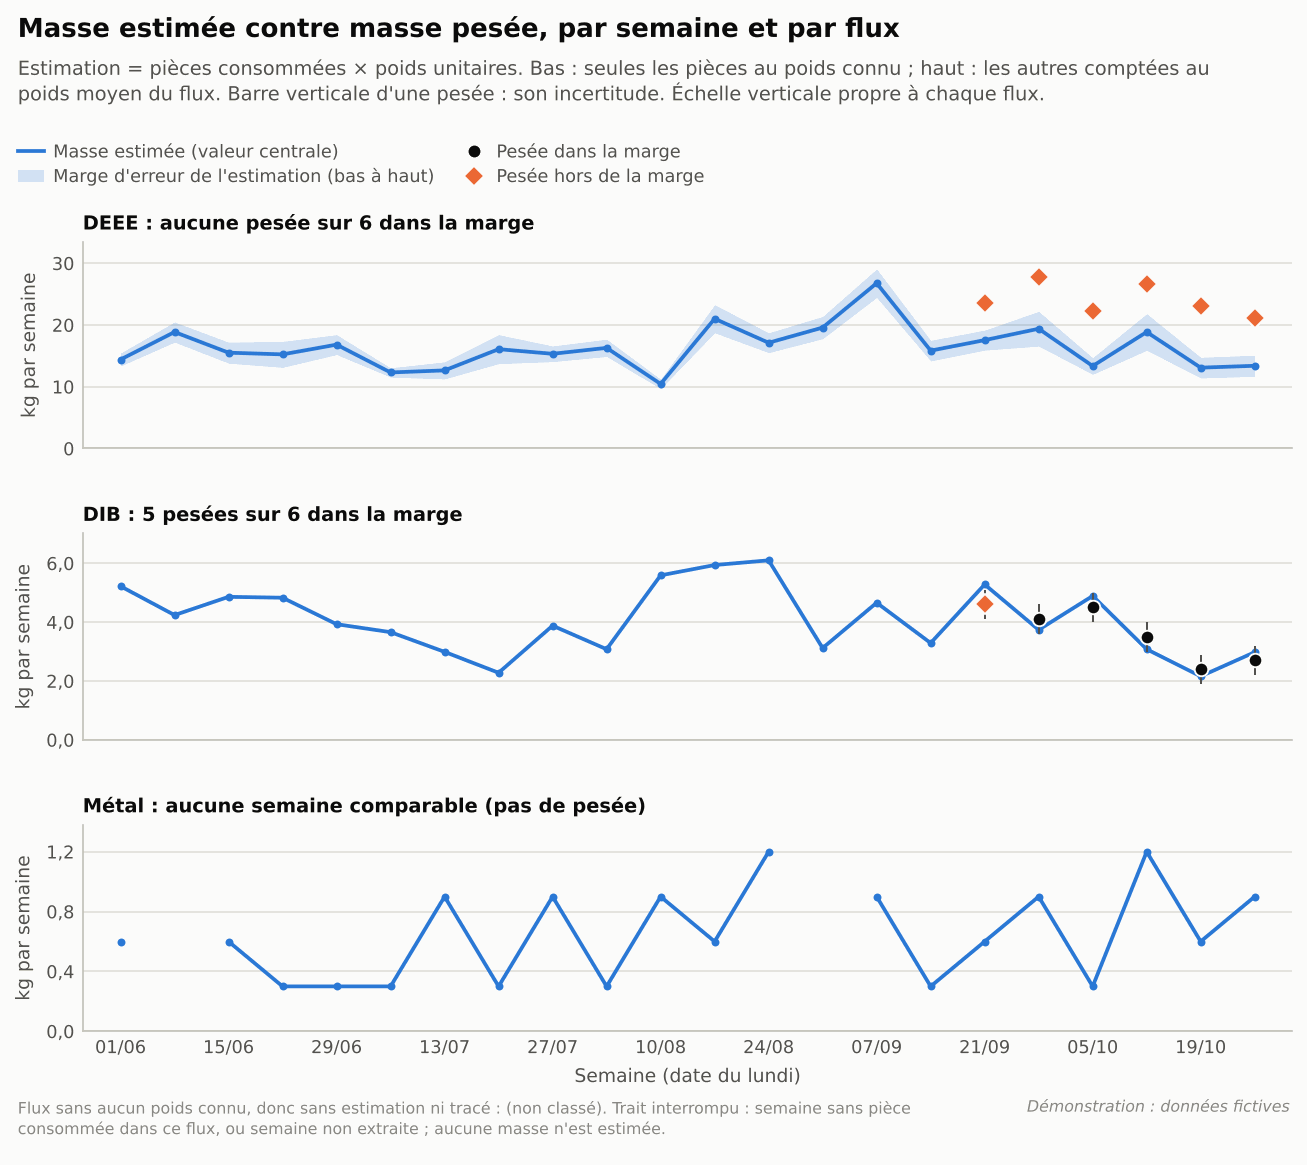

**Cumul estimé contre pesé.** Masse cumulée estimée et masse cumulée pesée, flux par flux, sur les semaines comparables. Lecture : deux courbes qui se suivent valident l'estimation ; deux courbes qui s'écartent régulièrement désignent une cause permanente (périmètre de la benne, poids manquants).

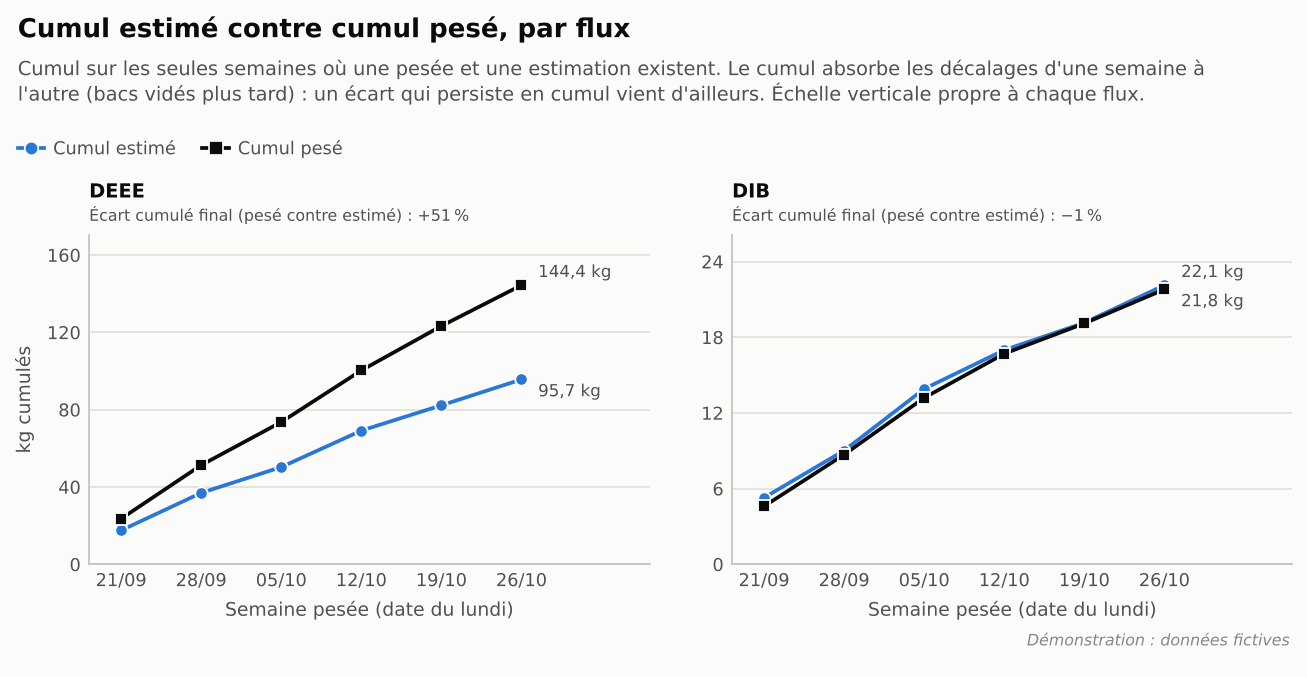

In [7]:
aff.figures(ctx, "flux", ["Estimé contre pesé", "Cumul estimé contre pesé"])

In [8]:
aff.table(ctx, "flux", "Estimé contre pesé", colonnes=colonnes + ["Estimé bas (kg)", "Estimé haut (kg)", "Couverture poids", "Jours extraits", "Périmètre", "Commentaire"])

Semaine,Flux,Estimé central (kg),Masse mesurée (kg),Marge d'erreur (± kg),Écart (%),Dans la marge,Écart cumulé (%),Cause constatée (à saisir),Causes candidates de l'écart,Estimé bas (kg),Estimé haut (kg),Couverture poids,Jours extraits,Périmètre,Commentaire
15/06/2026,(non classé),,,,,non comparable,,,pas de pesée cette semaine,,,"0,0 %",7,,
22/06/2026,(non classé),,,,,non comparable,,,pas de pesée cette semaine,,,"0,0 %",7,,
06/07/2026,(non classé),,,,,non comparable,,,pas de pesée cette semaine,,,"0,0 %",7,,
20/07/2026,(non classé),,,,,non comparable,,,pas de pesée cette semaine,,,"0,0 %",7,,
27/07/2026,(non classé),,,,,non comparable,,,pas de pesée cette semaine,,,"0,0 %",7,,
10/08/2026,(non classé),,,,,non comparable,,,pas de pesée cette semaine,,,"0,0 %",7,,
31/08/2026,(non classé),,,,,non comparable,,,pas de pesée cette semaine,,,"0,0 %",7,,
07/09/2026,(non classé),,,,,non comparable,,,pas de pesée cette semaine,,,"0,0 %",7,,
21/09/2026,(non classé),,,,,non comparable,,,pas de pesée cette semaine,,,"0,0 %",7,,
05/10/2026,(non classé),,,,,non comparable,,,pas de pesée cette semaine,,,"0,0 %",7,,


### Verdict par flux

Un flux est jugé **utilisable par le modèle** quand il compte au moins trois semaines comparées et que l'écart cumulé final ne dépasse pas 15 %. En dessous de trois semaines, il n'y a pas assez de pesées pour conclure ; au-delà de 15 %, il faut corriger la cause dominante avant d'aller plus loin.

**Décision éclairée** : poursuivre les pesées, élargir ou réduire le périmètre d'une benne, compléter les poids unitaires.

In [9]:
aff.table(ctx, "flux", "Verdict par flux")

Flux,Semaines comparées,Semaines dans la marge,Écart moyen (%),Écart cumulé final (%),Couverture poids moyenne,Utilisable par le modèle
DEEE,6,0,"53,2 %","51,0 %","77,8 %",non : corriger la cause dominante
DIB,6,5,"0,7 %","−1,5 %","100,0 %",oui


## FRU rebutées par semaine

C'est le flux d'entrée du modèle de ligne : nombre de FRU rebutées chaque semaine, par type. Une semaine extraite sans rebut compte pour zéro ; une semaine incomplète (moins de sept jours extraits) est signalée et ne sert pas au calcul du rebut annuel.

**Lecture** : l'irrégularité d'une semaine à l'autre compte autant que la moyenne. Une ligne dimensionnée sur la moyenne perd des heures les semaines creuses et laisse des FRU les semaines chargées (chiffré au notebook 05).

**FRU rebutées par semaine.** Le flux d'entrée du modèle de ligne : nombre de FRU rebutées chaque semaine, empilé par type de FRU (les cinq types les plus fréquents, puis les autres). Les semaines incomplètes sont hachurées et ne servent pas à calculer le rebut annuel.

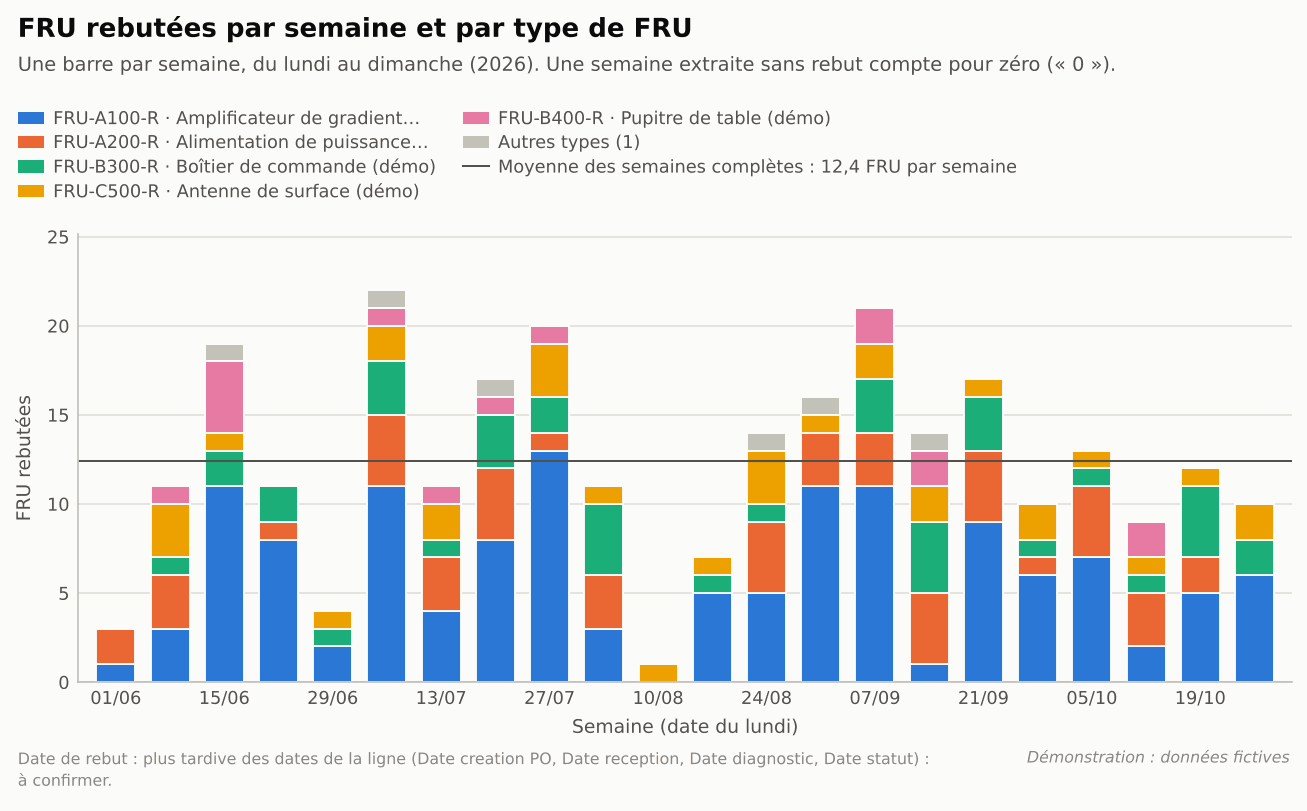

In [10]:
aff.figures(ctx, "flux", "FRU rebutées par semaine")

In [11]:
aff.table(ctx, "flux", "FRU rebutées par semaine", n=12)

Semaine,FRU,FRU rebutées,Jours extraits,Semaine complète,Poids FRU (kg),Masse estimée (kg)
01/06/2026,FRU-A100-R,1,7,oui,"79,00","79,0"
01/06/2026,FRU-A200-R,2,7,oui,"62,00","124,0"
01/06/2026,FRU-B300-R,0,7,oui,"5,50","0,0"
01/06/2026,FRU-B400-R,0,7,oui,"6,30","0,0"
01/06/2026,FRU-C500-R,0,7,oui,"3,00","0,0"
01/06/2026,FRU-W600-R,0,7,oui,"11,00","0,0"
08/06/2026,FRU-A100-R,3,7,oui,"79,00","237,0"
08/06/2026,FRU-A200-R,3,7,oui,"62,00","186,0"
08/06/2026,FRU-B300-R,1,7,oui,"5,50","5,5"
08/06/2026,FRU-B400-R,1,7,oui,"6,30","6,3"


## Rebut annuel par type de FRU

Moyenne hebdomadaire des semaines complètes × 52, avec un intervalle à 90 % obtenu en ré-échantillonnant les semaines observées. Ces trois valeurs (bas, moyen, haut) sont reprises par le modèle de ligne quand le rebut annuel n'est pas saisi dans le classeur de paramètres.

**Limite** : l'intervalle ne reflète que l'irrégularité des semaines observées. Une période courte, une saisonnalité ou un changement de politique de rebut n'y sont pas.

**Rebut annuel par type de FRU.** Le rebut annuel de chaque type de FRU, tiré du suivi hebdomadaire : point = estimation moyenne, trait = intervalle à 90 %. Un intervalle large dit que la période observée est trop courte ou le flux trop irrégulier pour dimensionner la ligne à l'unité près.

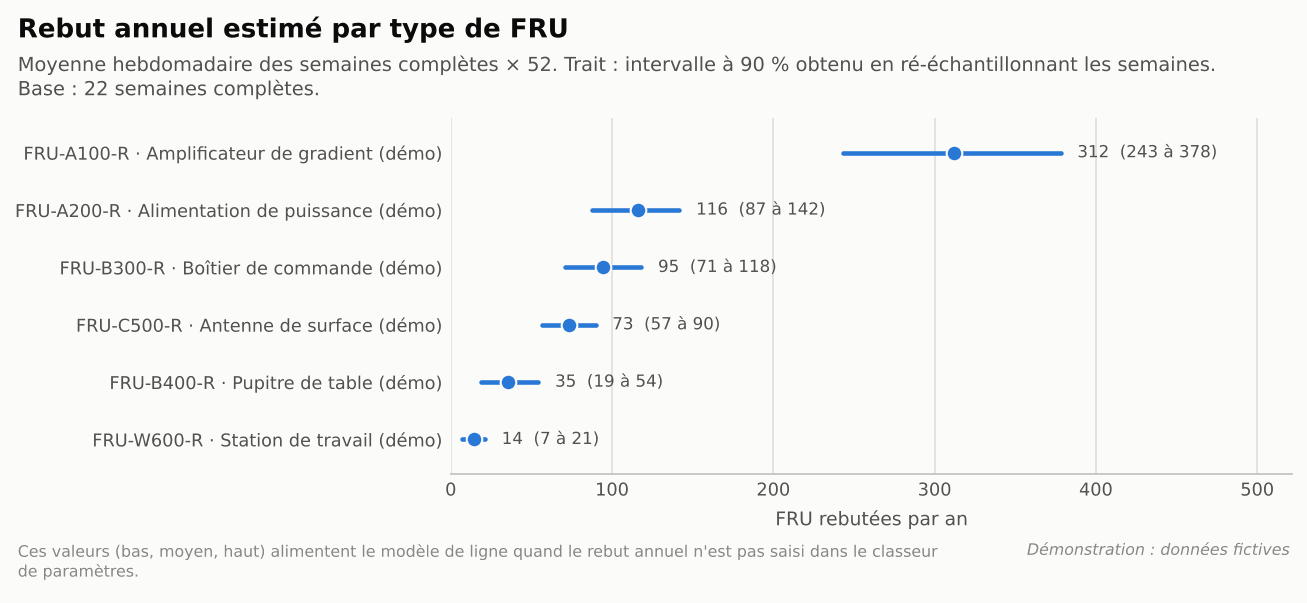

In [12]:
aff.figures(ctx, "flux", "Rebut annuel par type de FRU")

In [13]:
aff.table(ctx, "flux", "Rebut annuel", colonnes=["FRU", "Semaines complètes", "Moyenne hebdo", "Écart-type hebdo", "Rebut annuel bas (5 %)",
          "Rebut annuel moyen", "Rebut annuel haut (95 %)", "Note"])

FRU,Semaines complètes,Moyenne hebdo,Écart-type hebdo,Rebut annuel bas (5 %),Rebut annuel moyen,Rebut annuel haut (95 %),Note
FRU-A100-R,22,"6,00","3,84","243,5","312,0","378,2",
FRU-A200-R,22,"2,23","1,57","87,5","115,8","141,8",
FRU-B300-R,22,"1,82","1,30","70,9","94,5","118,2",
FRU-B400-R,22,"0,68","1,04","18,9","35,5","54,4",
FRU-C500-R,22,"1,41","0,91","56,7","73,3","89,8",
FRU-W600-R,22,"0,27","0,46","7,1","14,2","21,3",


## Notes de l'étape

Règle qui date un rebut, granularité du suivi (par benne ou par type de déchet), nombre de semaines pesées.

In [14]:
aff.notes(ctx, "flux")

Élément,Valeur
Date retenue pour le rebut,"plus tardive des dates de la ligne (Date creation PO, Date reception, Date diagnostic, Date statut) : à confirmer"
Granularité du suivi,Benne
Semaines pesées,6


---
Notebook suivant : **03_Fiabilite**. Tous les fichiers affichés ici sont dans le dossier des artefacts, étape `02_flux` ; un classeur Excel du même nom réunit les tables de l'étape.